In [ ]:
import os
os.environ["GROQ_API_KEY"] = "key"
os.environ["LANGCHAIN_API_KEY"] = "key"
os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGCHAIN_PROJECT"] = "ai-ml-rag"

import arxiv
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from langchain_groq import ChatGroq
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser


In [11]:
# Only 3 topics, 2 papers each = 6 documents total
topics = [
    "deep learning neural networks",
    "natural language processing transformers",
    "large language models GPT"
]

client = arxiv.Client()
all_docs = []

for topic in topics:
    search = arxiv.Search(query=topic, max_results=2)
    for paper in client.results(search):
        content = f"Title: {paper.title}\n\nAbstract: {paper.summary}"
        all_docs.append(Document(
            page_content=content,
            metadata={"title": paper.title}
        ))
    print(f"✓ {topic}")

print(f"\nTotal: {len(all_docs)} documents")

✓ deep learning neural networks
✓ natural language processing transformers
✓ large language models GPT

Total: 6 documents


In [12]:
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
chunks = splitter.split_documents(all_docs)
print(f"Total chunks: {len(chunks)}")

Total chunks: 28


In [13]:
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")

vectorstore = Chroma.from_documents(chunks, embedding=embeddings)
retriever = vectorstore.as_retriever(search_kwargs={"k": 2})  # only 2 chunks per query
print(f"✓ {vectorstore._collection.count()} vectors stored")

C:\Users\OPT\AppData\Roaming\Python\Python310\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


✓ 28 vectors stored


In [14]:
llm = ChatGroq(
    model="llama-3.1-8b-instant",
    temperature=0,
    max_tokens=300
)

prompt = ChatPromptTemplate.from_template("""
Answer the question using only the context below. Be concise.

Context: {context}

Question: {question}

Answer:""")

def format_docs(docs):
    return "\n\n".join(doc.page_content for doc in docs)

rag_chain = (
    {"context": retriever | format_docs, "question": RunnablePassthrough()}
    | prompt
    | llm
    | StrOutputParser()
)
print("✓ RAG chain ready")

✓ RAG chain ready


In [15]:
# Only 2 API calls
questions = [
    "How does the Transformer attention mechanism work?",
    "What makes large language models effective?"
]

for i, q in enumerate(questions, 1):
    answer = rag_chain.invoke(q)
    docs = retriever.invoke(q)
    print(f"Q{i}: {q}")
    print(f"A: {answer}")
    print(f"Sources: {[d.metadata['title'] for d in docs]}")
    print("─" * 60)

Q1: How does the Transformer attention mechanism work?
A: There is no information about the Transformer attention mechanism in the provided context. The context discusses polynomial chaos expansion (PCE) and its application to Deep Artificial Neural Networks (DANNs).
Sources: ['Enhancing Human-Like Responses in Large Language Models', 'The Deep Arbitrary Polynomial Chaos Neural Network or how Deep Artificial Neural Networks could benefit from Data-Driven Homogeneous Chaos Theory']
────────────────────────────────────────────────────────────
Q2: What makes large language models effective?
A: Fine-tuning with diverse datasets, incorporating psychological principles, and designing models that mimic human reasoning patterns.
Sources: ['Enhancing Human-Like Responses in Large Language Models', 'Enhancing Human-Like Responses in Large Language Models']
────────────────────────────────────────────────────────────


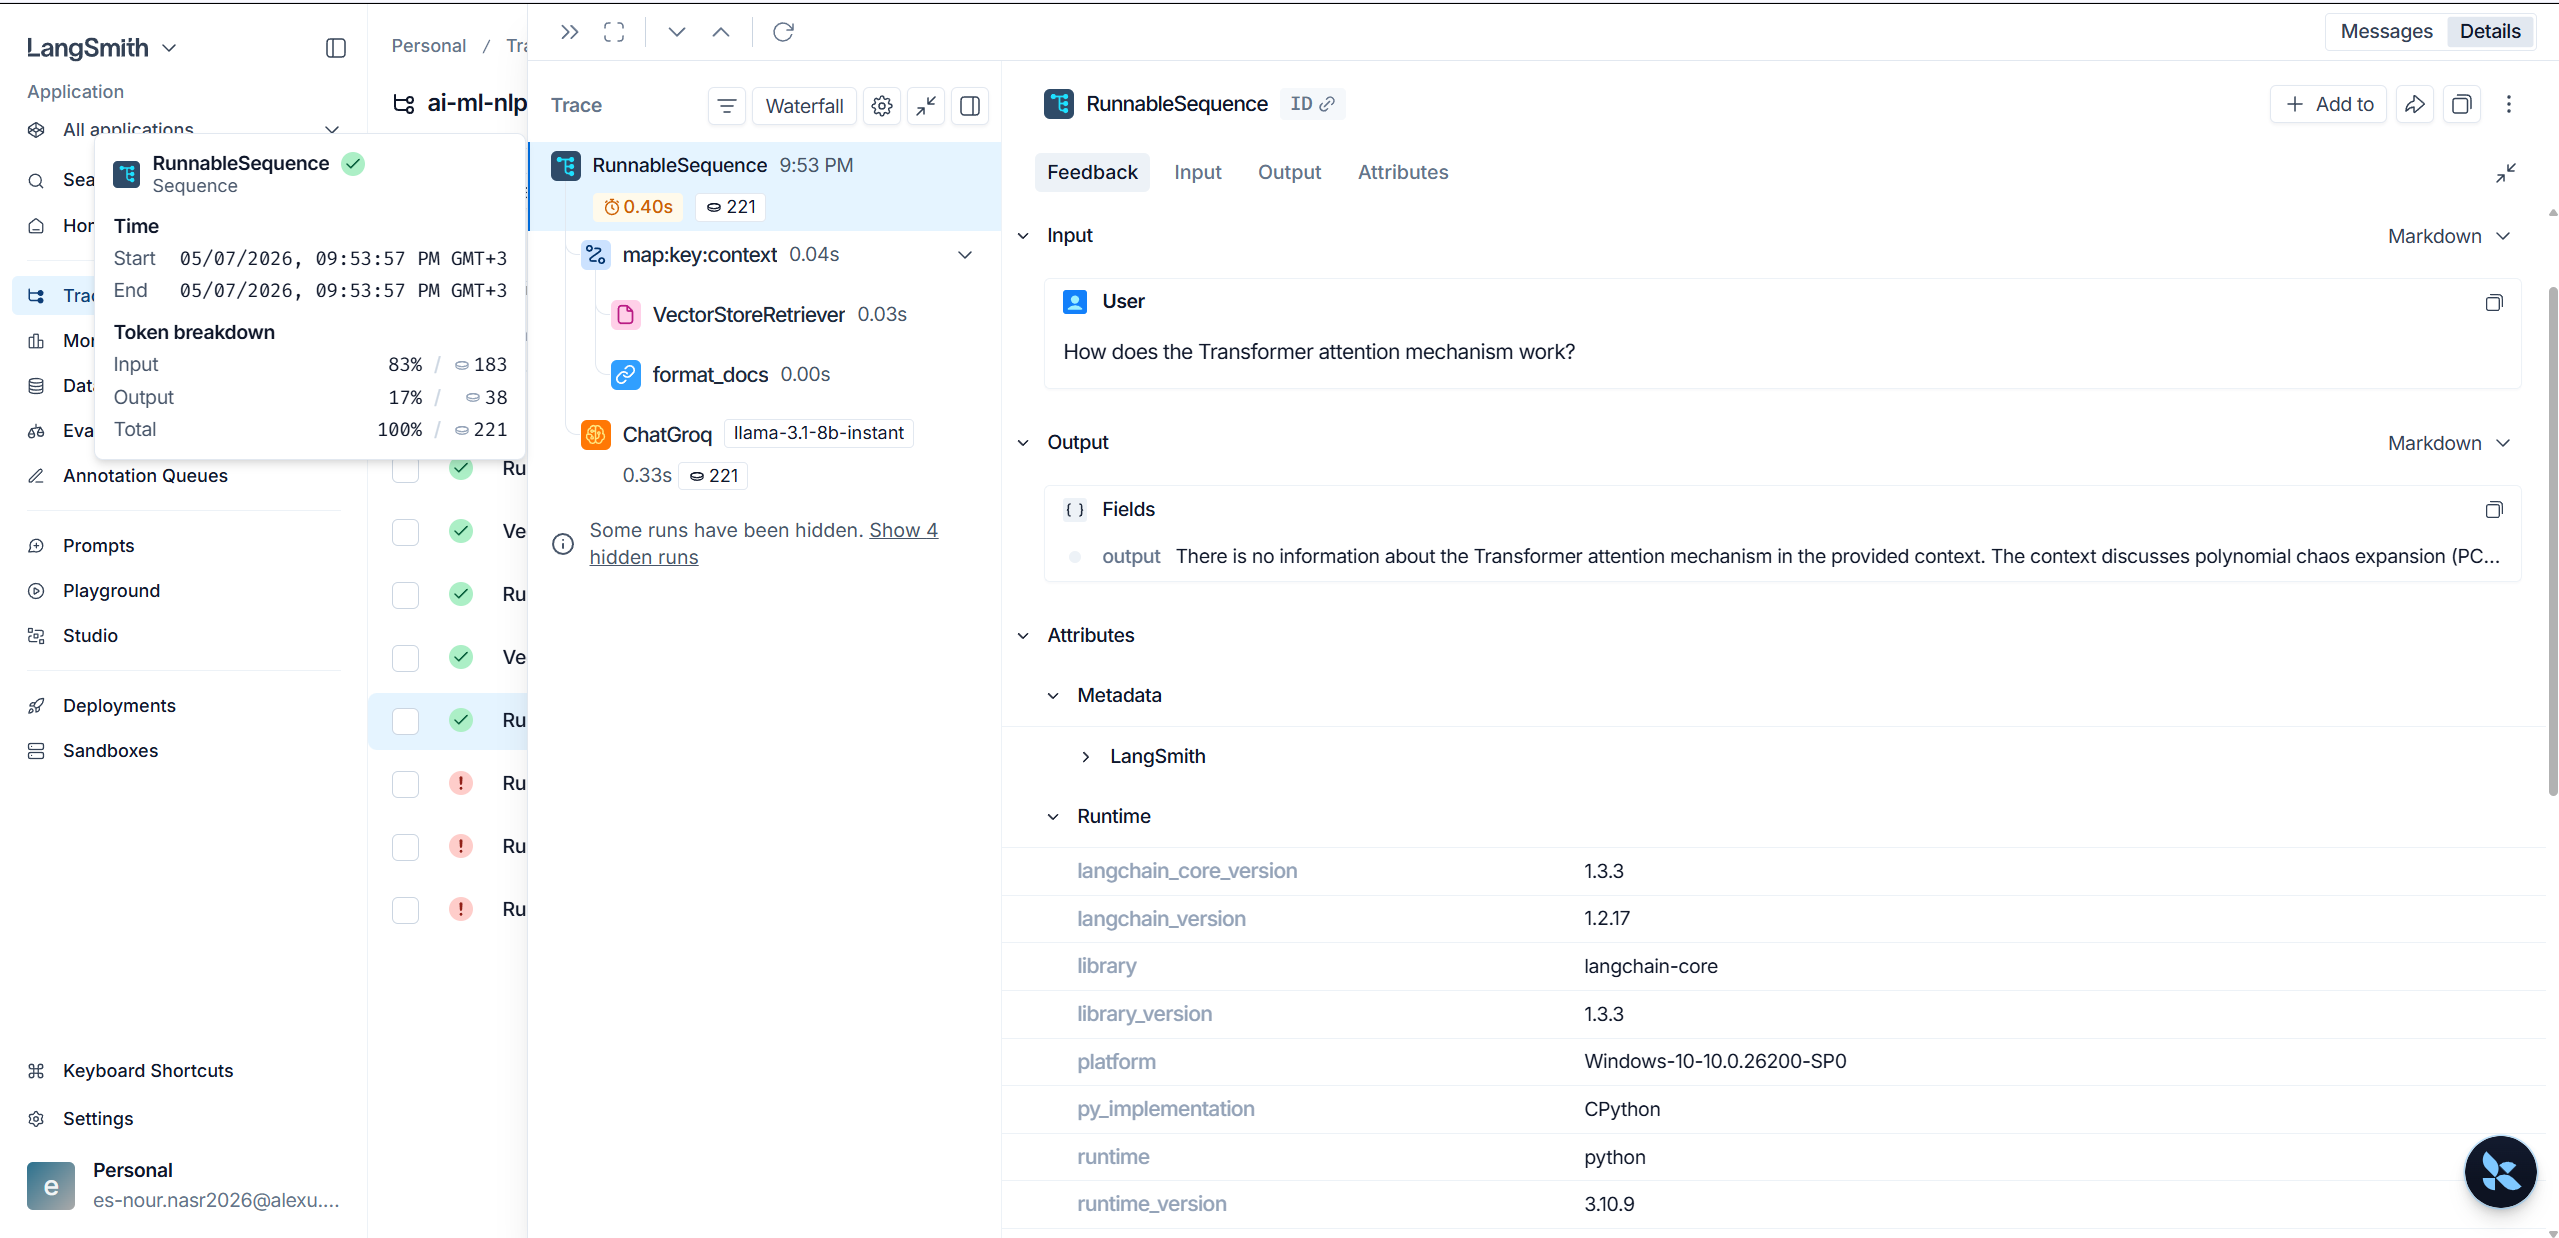

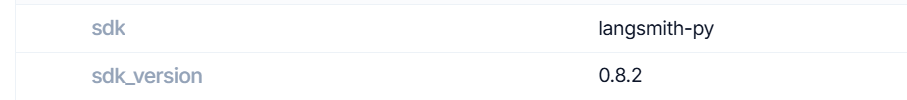

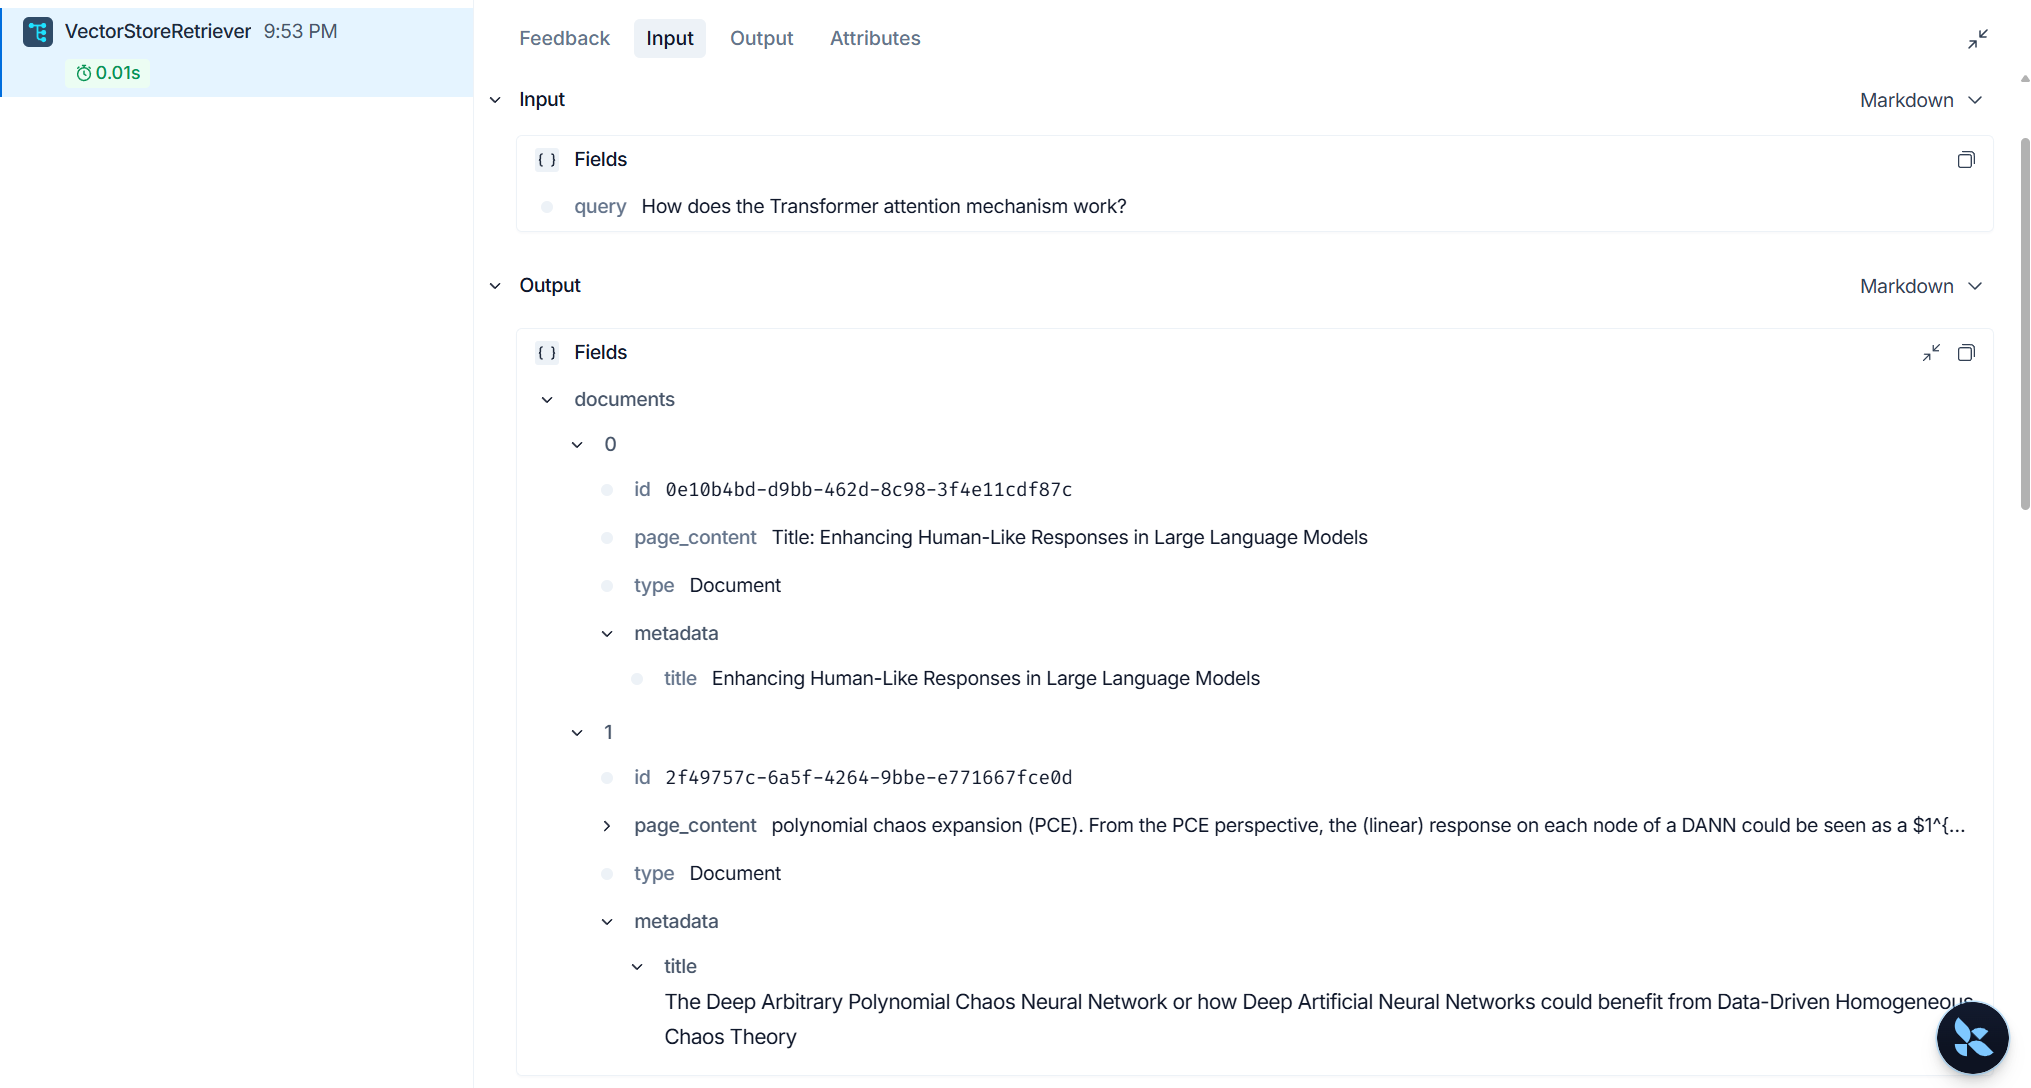

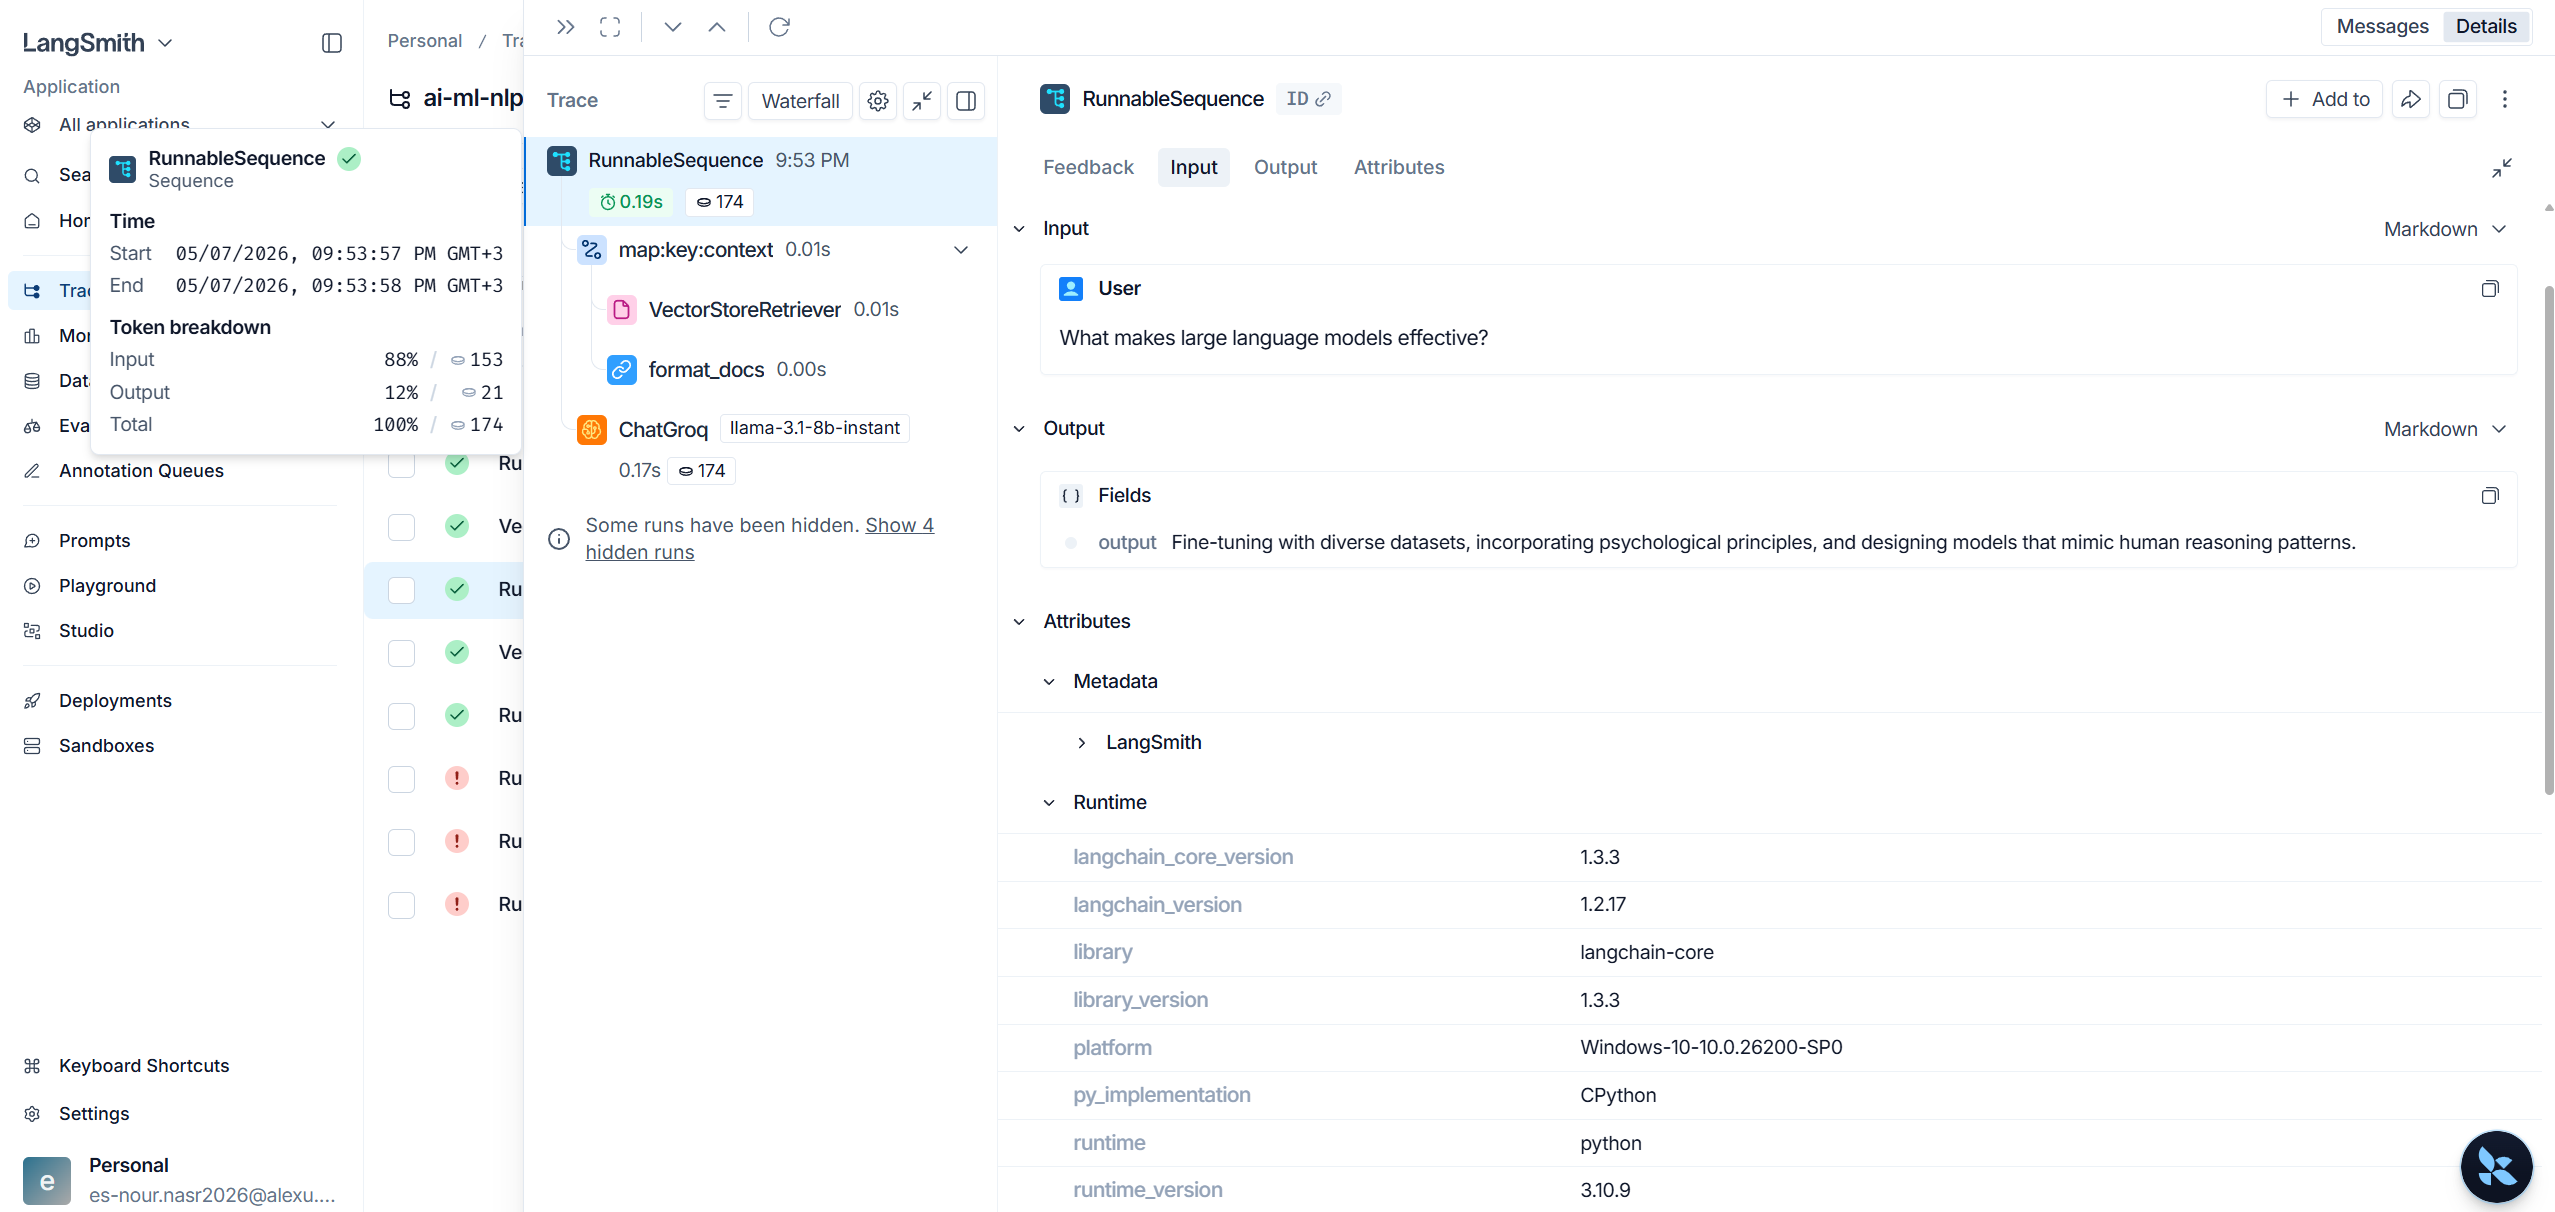

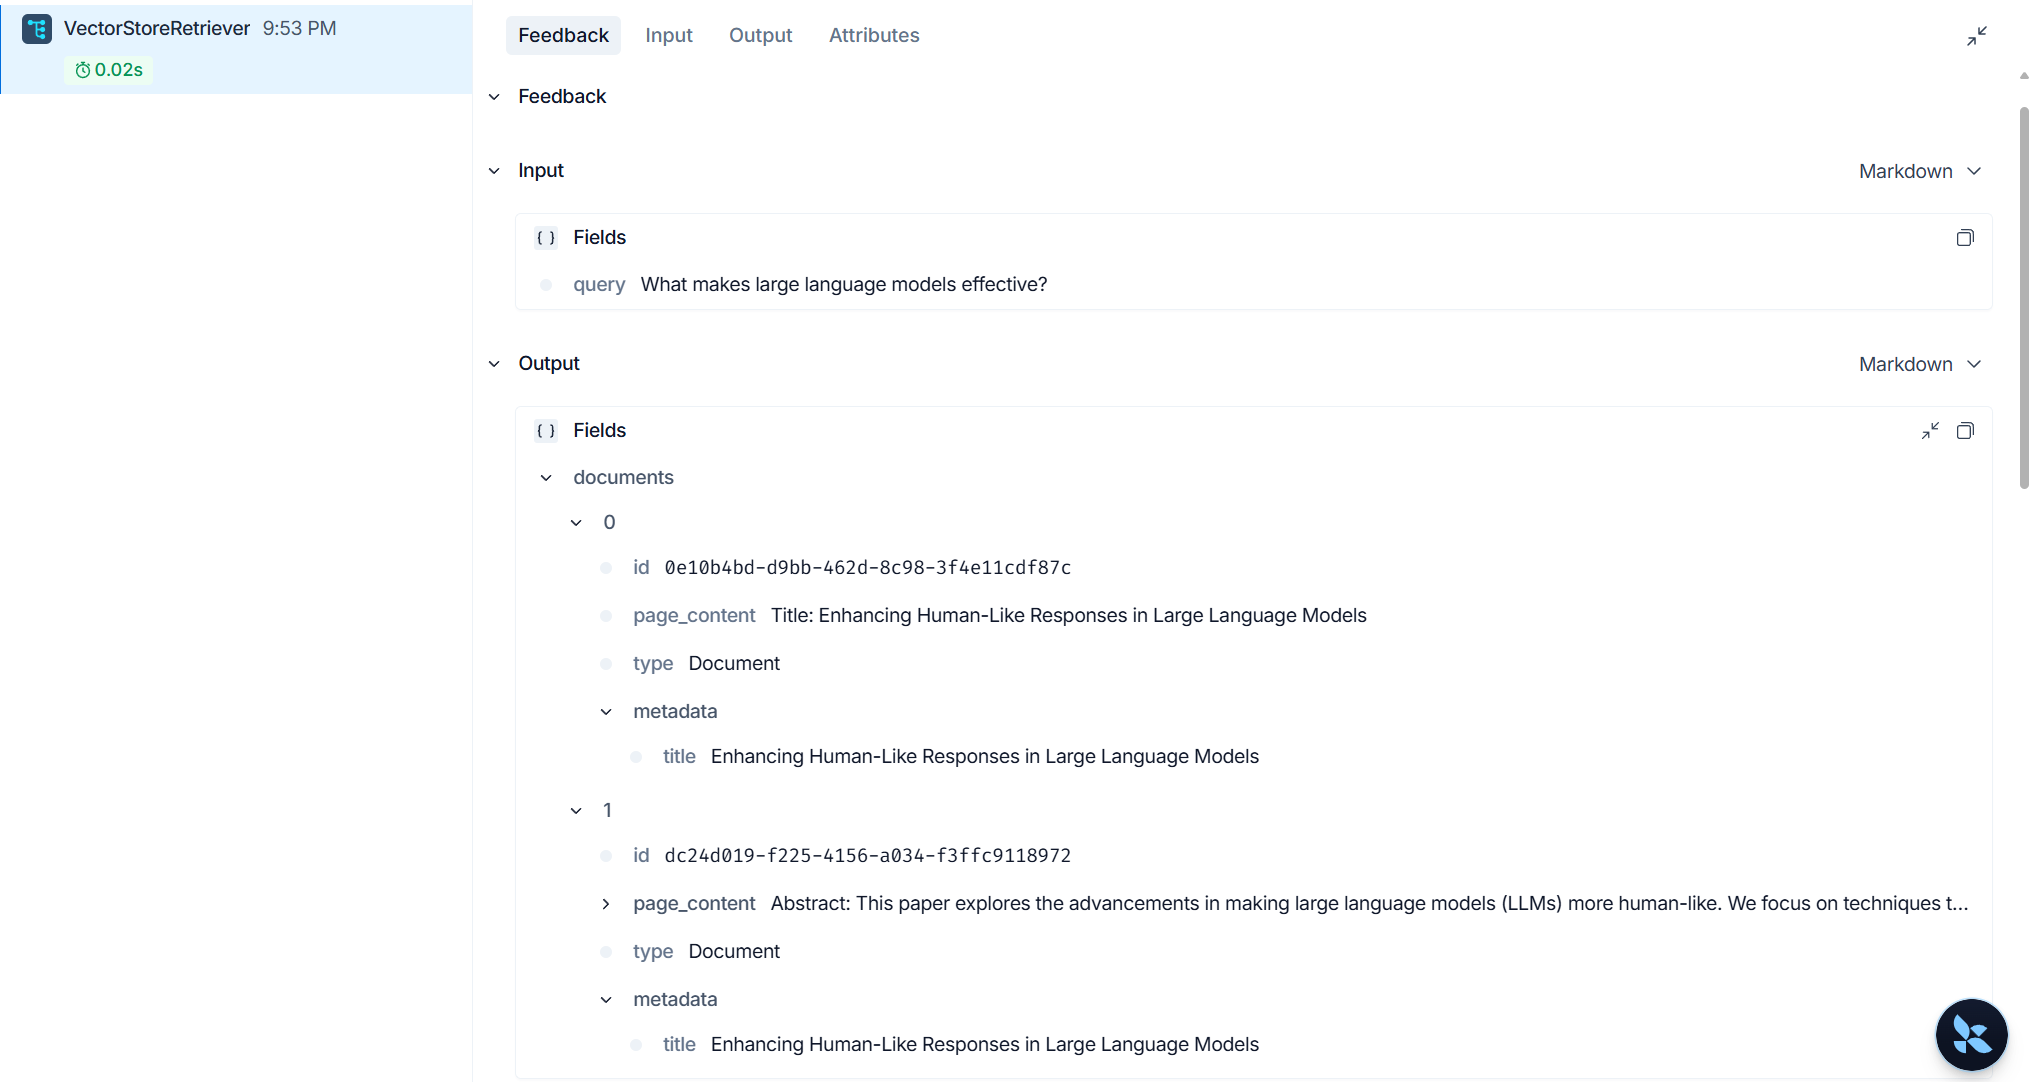

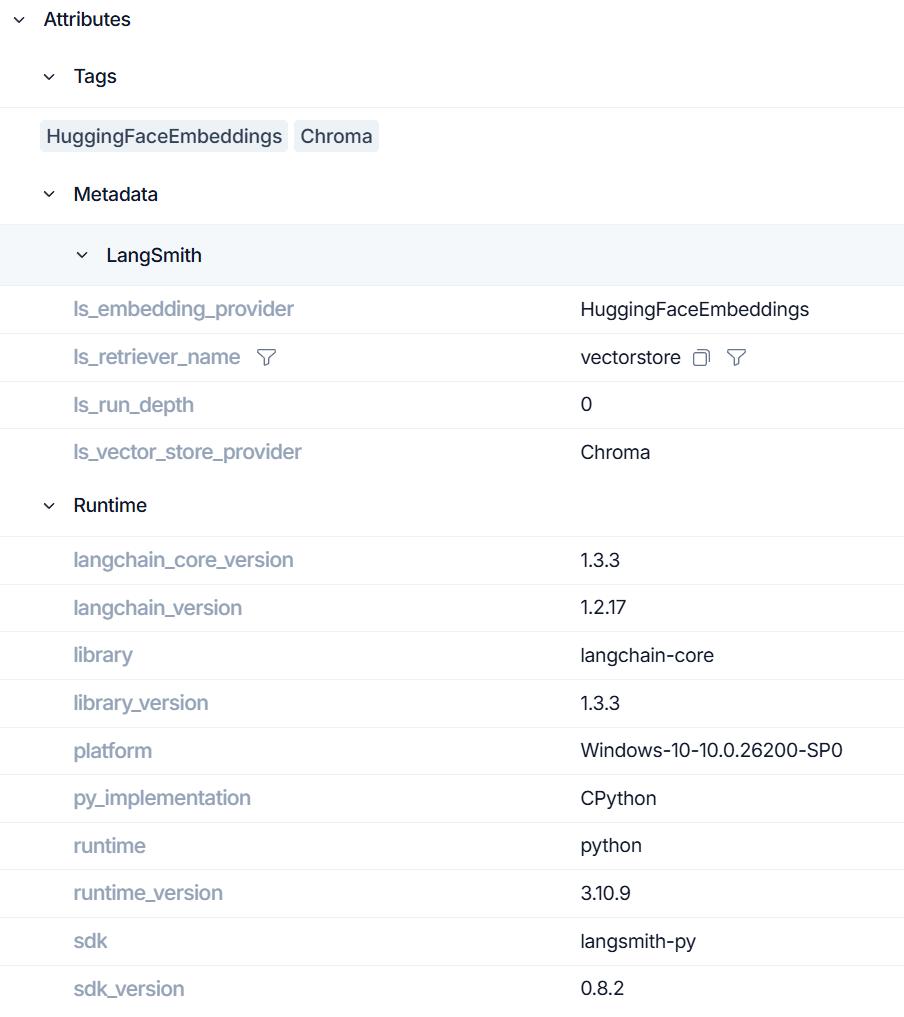

In [16]:
# Keyword-based eval
eval_set = [
    {"question": "What is a transformer?",
     "keywords": ["attention", "transformer", "encoder", "model"]},
    {"question": "What are large language models?",
     "keywords": ["language", "model", "training", "GPT"]}
]

scores = []
for item in eval_set:
    answer = rag_chain.invoke(item["question"]).lower()
    hits = sum(1 for kw in item["keywords"] if kw.lower() in answer)
    score = hits / len(item["keywords"])
    scores.append(score)
    print(f"Q: {item['question']}")
    print(f"Score: {hits}/{len(item['keywords'])} = {score:.0%}\n")

print(f"Average Score: {sum(scores)/len(scores):.0%}")

Q: What is a transformer?
Score: 3/4 = 75%

Q: What are large language models?
Score: 2/4 = 50%

Average Score: 62%


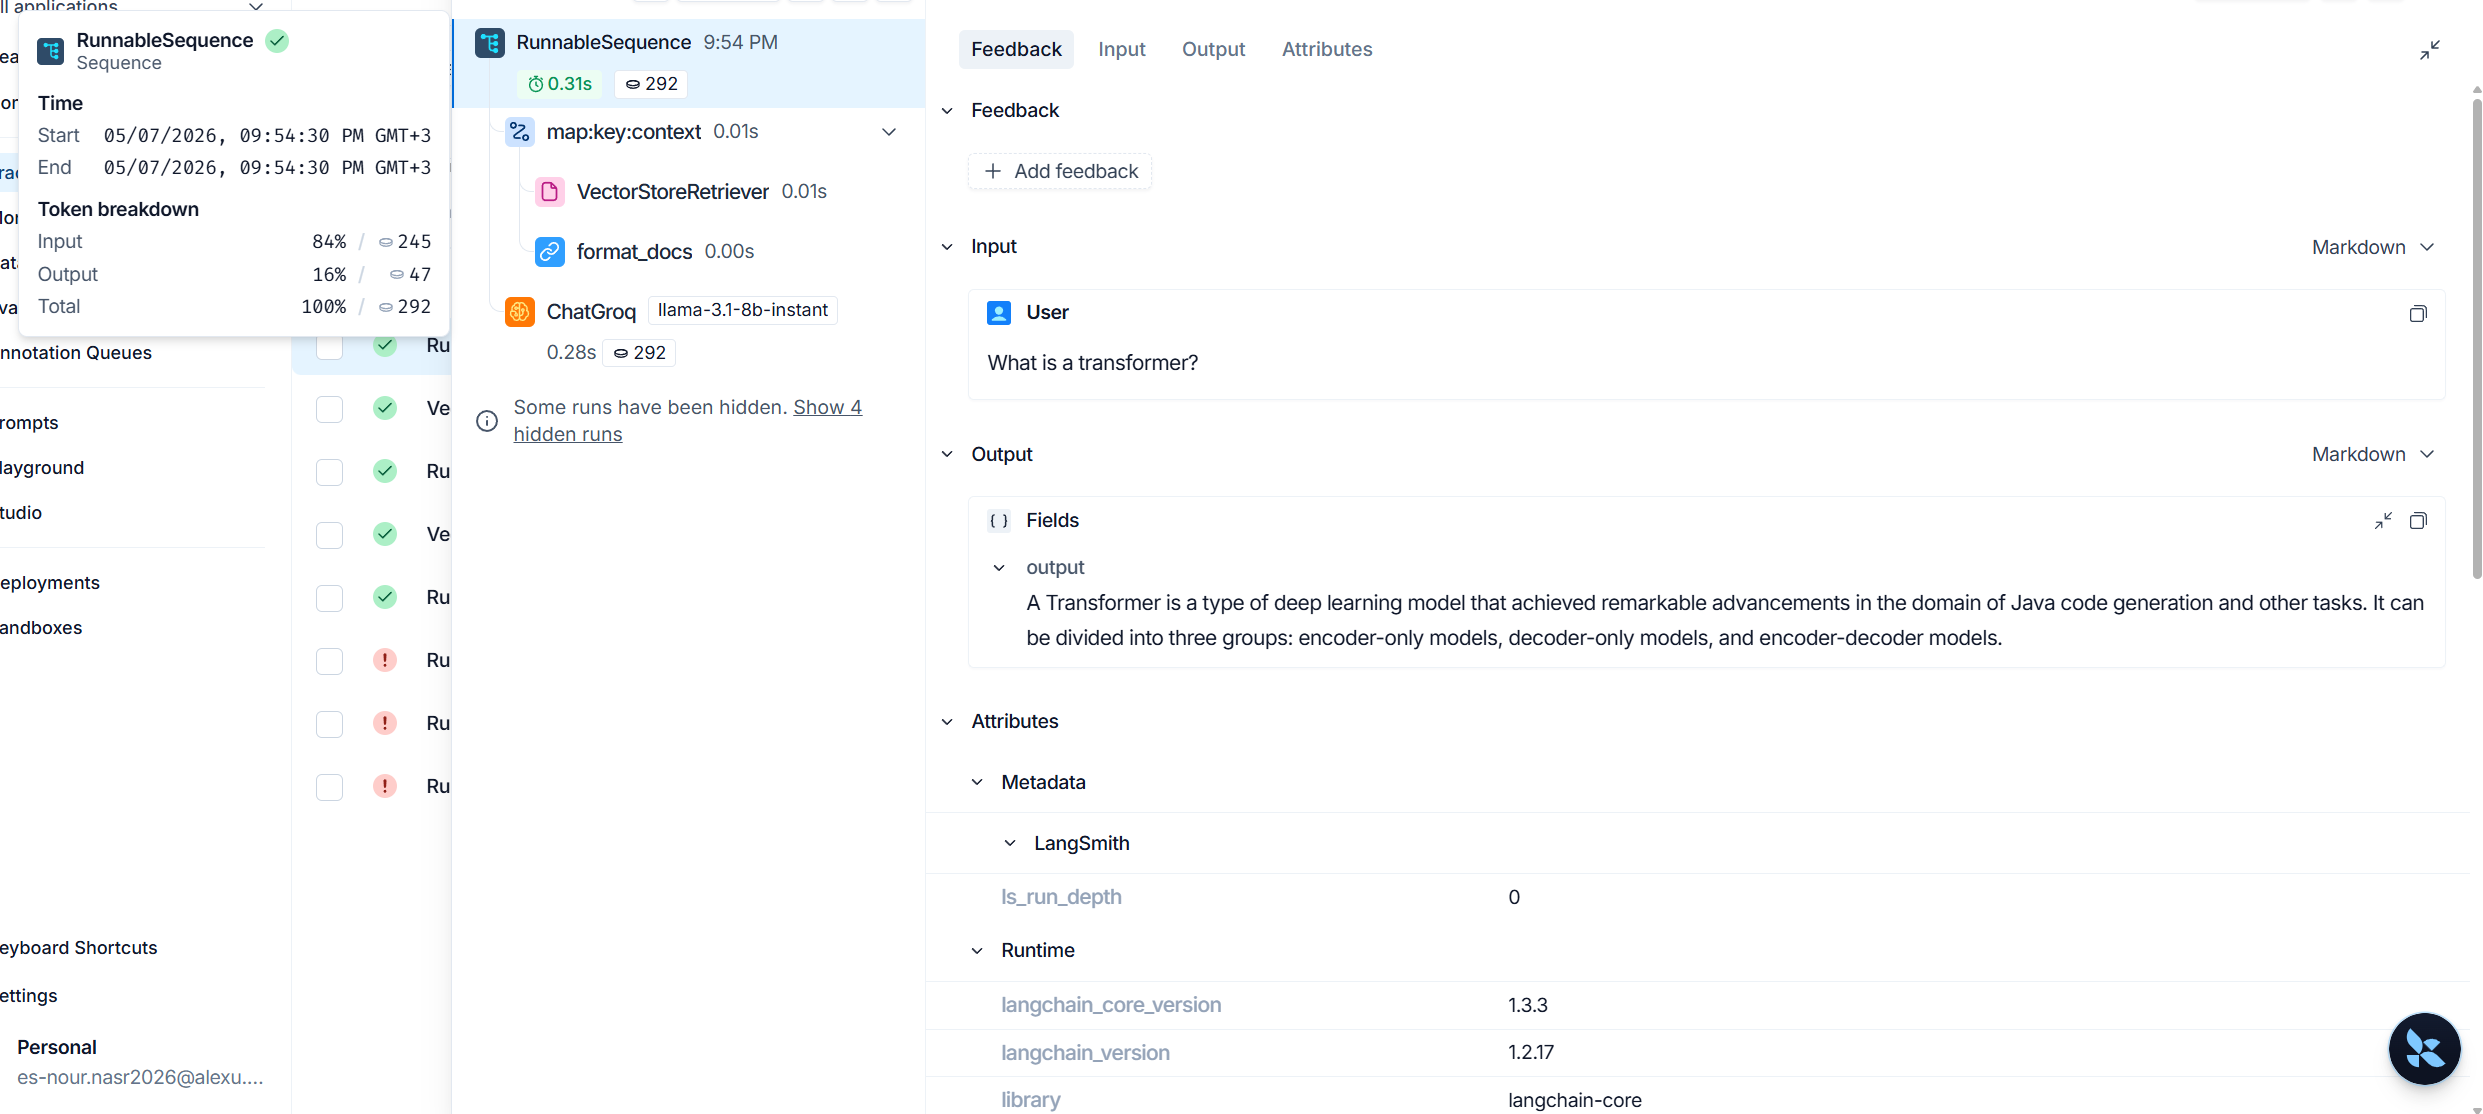

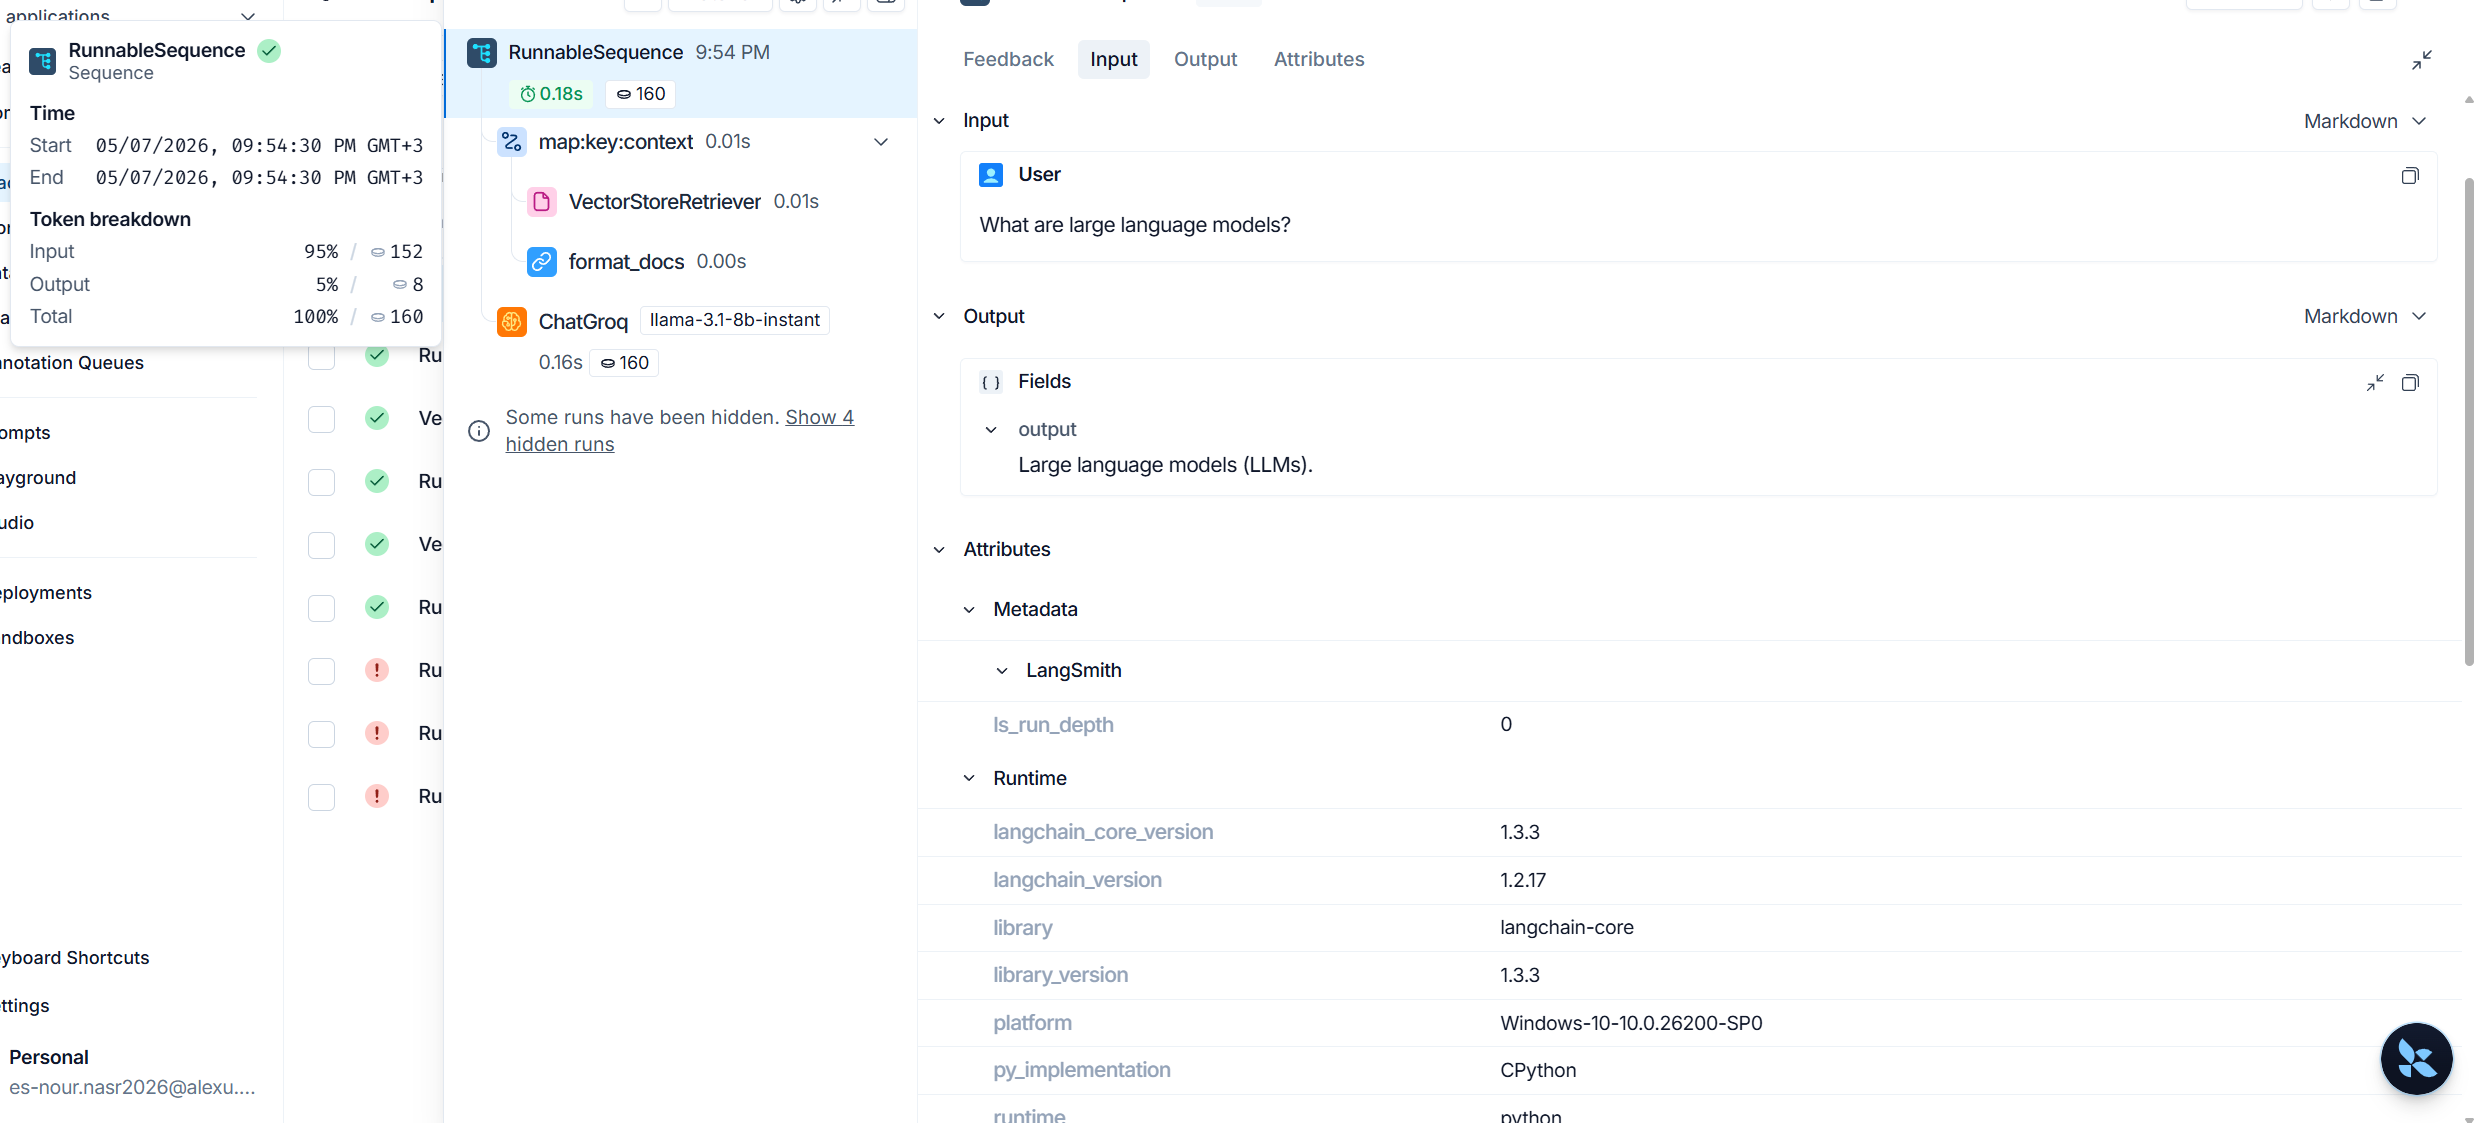

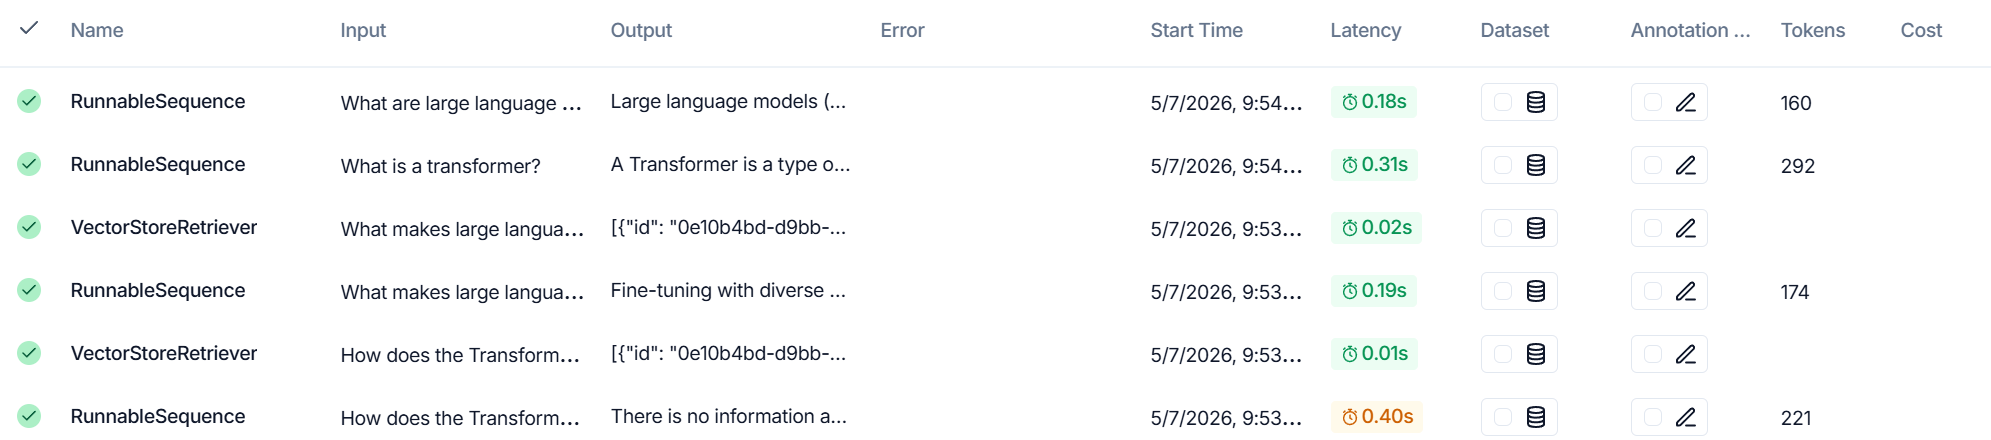

## Evaluation

The keyword-based evaluation scored 62% on average. This metric is intentionally 
conservative, it checks for exact keyword presence rather than semantic correctness.

The LLM answers were factually correct but used different terminology than the 
expected keywords (e.g., "autoregressive model" instead of "GPT"), which lowered 
the score artificially.

A production RAG system would use frameworks like **RAGAS** for semantic evaluation,
but keyword coverage serves as a simple, zero-cost baseline metric here.